# Сравнение моделей SASRec и DreamRec.

Full-rank метрики (HR@K, NDCG@K) всех обученных моделей в одной таблице. Каждая модель
собирается по своему yaml через реестр `builders.MODELS`, веса берутся из чекпойнта,
сэмплинг идёт с параметрами из конфига этой модели — то есть ровно так, как её оценивал
тренер. Разброс считается по сидам сэмплинга; у SASRec сэмплинга нет, поэтому std = 0.

Чтобы добавить или убрать модель — правь словарь `RUNS` ниже.

In [1]:
import os, random, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)                          # пути в yaml относительны корня проекта
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from builders import load_model_config
from data import build_dataloaders
from evaluate import evaluate
from train import seeded

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Корень проекта: {ROOT} | device: {device}')

Корень проекта: d:\Skoltech\Thesis\DiffText4Rec | device: cuda


## Какие чекпойнты сравнивать

`config` — yaml, с которым обучалась модель (из него берётся и тип модели, и параметры
сэмплинга), `ckpt` — папка с `best.pt` / `latest.pt`.

In [2]:
# ════════════════════════════════════════════════════════════
# КОНФИГ
# ════════════════════════════════════════════════════════════
RUNS = {
    'SASRec':         {'config': 'configs/sasrec.yaml',           'ckpt': 'checkpoints/sasrec'},
    'DreamRec':       {'config': 'configs/dreamrec.yaml',         'ckpt': 'checkpoints/dreamrec'},
    'DreamRecText':   {'config': 'configs/dreamrec_text.yaml',    'ckpt': 'checkpoints/dreamrec_text'},
    'DreamRecFMText': {'config': 'configs/dreamrec_fm_text.yaml', 'ckpt': 'checkpoints/dreamrec_fm_text'},
}

# Подписи на графиках; ключ — имя из RUNS, модель без записи подписывается своим именем
LABELS = {
    'SASRec':         'SASRec',
    'DreamRec':       'Learned_DDPM',
    'DreamRecText':   'Frozen_DDPM',
    'DreamRecFMText': 'Frozen_FM',
}

TOP_K  = (10, 20)   # общие столбцы таблицы для всех моделей
N_RUNS = 5          # прогонов сэмплинга для mean ± std
SEED   = 42         # EVAL_SEED тренера: с этим сидом метрики совпадают с логом обучения

METRICS = [f'{prefix}@{k}' for k in TOP_K for prefix in ('HR', 'NDCG')]

## Сборка моделей и загрузка весов

In [3]:
# ════════════════════════════════════════════════════════════
# Модели, лоадеры и параметры сэмплинга
# ════════════════════════════════════════════════════════════
_loader_cache = {}

def loaders_for(cfg):
    """Лоадеры под конкретный конфиг: batch_size влияет на нарезку потока шума,
    поэтому у каждой модели он свой — тот же, что при её обучении."""
    key = (cfg.data.data_dir, cfg.data.batch_size, cfg.data.max_seq_len)
    if key not in _loader_cache:
        _loader_cache[key] = build_dataloaders(data_dir=cfg.data.data_dir, batch_size=cfg.data.batch_size,
                                               num_workers=0, seq_len=cfg.data.max_seq_len,
                                               splits=('val', 'test'))
    return _loader_cache[key]


models = {}
for name, run in RUNS.items():
    ckpt_path = Path(run['ckpt']) / 'best.pt'
    if not ckpt_path.exists():
        ckpt_path = Path(run['ckpt']) / 'latest.pt'
    if not ckpt_path.exists():
        print(f'{name:<15} пропущен: нет best.pt/latest.pt в {run["ckpt"]}')
        continue

    spec, cfg = load_model_config(run['config'])
    model = spec.build(cfg).to(device).eval()
    ckpt  = torch.load(ckpt_path, map_location='cpu', mmap=True)
    model.load_state_dict(ckpt['model_state'])

    models[name] = {
        'model':      model,
        'cfg':        cfg,
        'loaders':    loaders_for(cfg),
        'ckpt_dir':   Path(run['ckpt']),
        'num_steps':  cfg.eval.num_sample_steps or 1,      # SASRec не сэмплирует
        'w_cfg':      getattr(cfg.model, 'w_cfg', 0.0),
        'generative': cfg.model_type != 'sasrec',
        'ckpt_ndcg20': ckpt['metrics']['NDCG@20'],
    }
    print(f'{name:<15} {cfg.model_type:<17} эпоха {ckpt["epoch"]:<4} '
          f'params {model.param_summary()["total_trainable"]:>11,}  '
          f'шагов {models[name]["num_steps"]:<4} w_cfg {models[name]["w_cfg"]}  '
          f'val NDCG@20 в чекпойнте {models[name]["ckpt_ndcg20"]:.4f}')

print(f'\nЗагружено моделей: {len(models)}')

SASRec          sasrec            эпоха 90   params   1,627,520  шагов 1    w_cfg 0.0  val NDCG@20 в чекпойнте 0.0345
DreamRec        dreamrec          эпоха 250  params 142,095,616  шагов 50   w_cfg 0.0  val NDCG@20 в чекпойнте 0.0363
Item embeddings: (11924, 3072)
Loading whitening from cache: data\processed\whitening_cache_k3072_pc.npz
DreamRecText    dreamrec_text     эпоха 210  params 110,181,376  шагов 50   w_cfg 0.0  val NDCG@20 в чекпойнте 0.0348
Item embeddings: (11924, 3072)
Loading whitening from cache: data\processed\whitening_cache_k3072_pc.npz
DreamRecFMText  dreamrec_fm_text  эпоха 80   params 110,181,376  шагов 50   w_cfg 0.0  val NDCG@20 в чекпойнте 0.0322

Загружено моделей: 4


## Метрики

`evaluate()` под сидами 42, 142, … — как финальная оценка в `train.py`. Первый сид
воспроизводит строку из `log_val.csv`, поэтому столбец «в чекпойнте» служит проверкой:
если он расходится со средним больше чем на пару std, модель собрана не тем конфигом.

In [4]:
# ════════════════════════════════════════════════════════════
# Оценка: N_RUNS сидов сэмплинга на val и test
# ════════════════════════════════════════════════════════════
seeds   = [SEED + 100 * i for i in range(N_RUNS)]
results = {'val': {}, 'test': {}}      # split → модель → метрика → значения по сидам

for name, entry in models.items():
    print(f'{name}...', end=' ', flush=True)
    for split in ('val', 'test'):
        runs = []
        for seed in seeds:
            with seeded(seed, device):
                runs.append(evaluate(model=entry['model'], dataloader=entry['loaders'][split],
                                     top_k_values=TOP_K, num_sample_steps=entry['num_steps'],
                                     w_cfg=entry['w_cfg'], device=device, show_progress=False))
            if not entry['generative']:
                break              # без сэмплинга все сиды дадут одно и то же
        results[split][name] = {m: [r[m] for r in runs] for m in METRICS}
    print('готово')

check = pd.DataFrame({
    name: {'val NDCG@20 (чекпойнт)': entry['ckpt_ndcg20'],
           'val NDCG@20 (сид 42)':   results['val'][name]['NDCG@20'][0]}
    for name, entry in models.items()}).T
print()
print(check.to_string(float_format=lambda x: f'{x:.4f}'))

SASRec... готово
DreamRec... готово
DreamRecText... готово
DreamRecFMText... готово

                val NDCG@20 (чекпойнт)  val NDCG@20 (сид 42)
SASRec                          0.0345                0.0345
DreamRec                        0.0363                0.0363
DreamRecText                    0.0348                0.0348
DreamRecFMText                  0.0322                0.0322


In [5]:
def random_row():
    """Аналитический бейзлайн: случайная перестановка каталога."""
    n = next(iter(models.values()))['model'].n_items if models else 1
    row = {}
    for k in TOP_K:
        row[f'HR@{k}']   = k / n
        row[f'NDCG@{k}'] = sum(1.0 / np.log2(r + 2) for r in range(k)) / n
    return row


def mean_std_table(split):
    """Строки — модели, ячейки — 'mean ± std' по сидам сэмплинга."""
    rows = {name: {m: f'{np.mean(vals[m]):.4f} ± {np.std(vals[m]):.4f}' for m in METRICS}
            for name, vals in results[split].items()}
    rows['Random'] = {m: f'{v:.4f}' for m, v in random_row().items()}
    df = pd.DataFrame(rows).T[METRICS]
    df.index.name = 'Model'
    return df


for split in ('val', 'test'):
    print(f'=== {split.upper()} (mean ± std по {N_RUNS} сидам сэмплинга) ===')
    print(mean_std_table(split).to_string())
    print()

=== VAL (mean ± std по 5 сидам сэмплинга) ===
                          HR@10          NDCG@10            HR@20          NDCG@20
Model                                                                             
SASRec          0.0474 ± 0.0000  0.0310 ± 0.0000  0.0613 ± 0.0000  0.0345 ± 0.0000
DreamRec        0.0472 ± 0.0007  0.0354 ± 0.0004  0.0542 ± 0.0010  0.0372 ± 0.0005
DreamRecText    0.0441 ± 0.0009  0.0329 ± 0.0002  0.0500 ± 0.0009  0.0343 ± 0.0003
DreamRecFMText  0.0391 ± 0.0012  0.0296 ± 0.0002  0.0461 ± 0.0022  0.0313 ± 0.0007
Random                   0.0008           0.0004           0.0017           0.0006

=== TEST (mean ± std по 5 сидам сэмплинга) ===
                          HR@10          NDCG@10            HR@20          NDCG@20
Model                                                                             
SASRec          0.0479 ± 0.0000  0.0288 ± 0.0000  0.0685 ± 0.0000  0.0339 ± 0.0000
DreamRec        0.0528 ± 0.0007  0.0377 ± 0.0004  0.0576 ± 0.0011  0.0388 ± 

## Сравнение моделей на графике

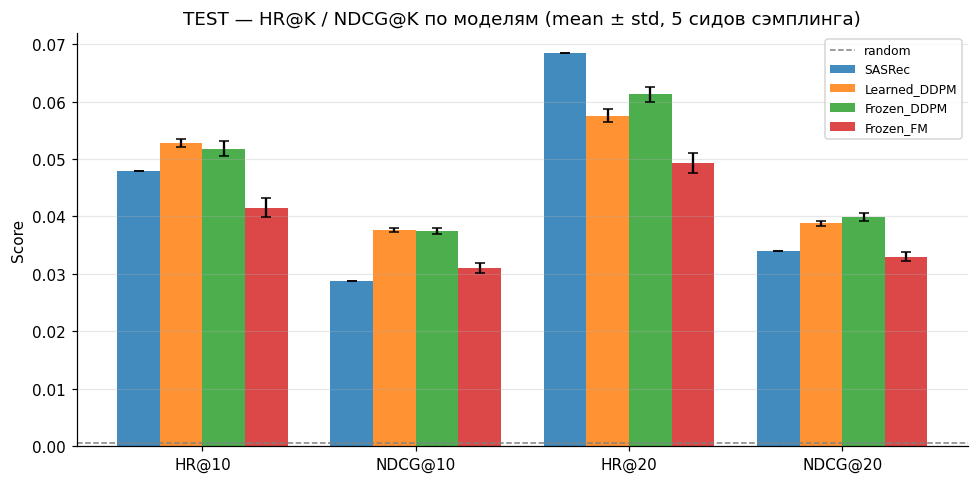

In [6]:
# ════════════════════════════════════════════════════════════
# Столбчатая диаграмма: test
# ════════════════════════════════════════════════════════════
names = list(models)
x     = np.arange(len(METRICS))
width = 0.8 / max(len(names), 1)

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, name in enumerate(names):
    vals = [np.mean(results['test'][name][m]) for m in METRICS]
    errs = [np.std(results['test'][name][m])  for m in METRICS]
    ax.bar(x + i * width, vals, width, yerr=errs, capsize=3,
           label=LABELS.get(name, name), alpha=0.85)
ax.axhline(random_row()['NDCG@20'], color='gray', ls='--', lw=1, label='random')
ax.set_xticks(x + width * (len(names) - 1) / 2); ax.set_xticklabels(METRICS)
ax.set_ylabel('Score'); ax.grid(axis='y', alpha=0.3); ax.legend(fontsize=8)
ax.set_title(f'TEST — HR@K / NDCG@K по моделям (mean ± std, {N_RUNS} сидов сэмплинга)')
plt.tight_layout(); plt.show()

## Кривые обучения

`log_val.csv` из папки каждого чекпойнта. Точки стоят реже, чем эпохи: валидация идёт
раз в `eval.every_epochs` эпох.

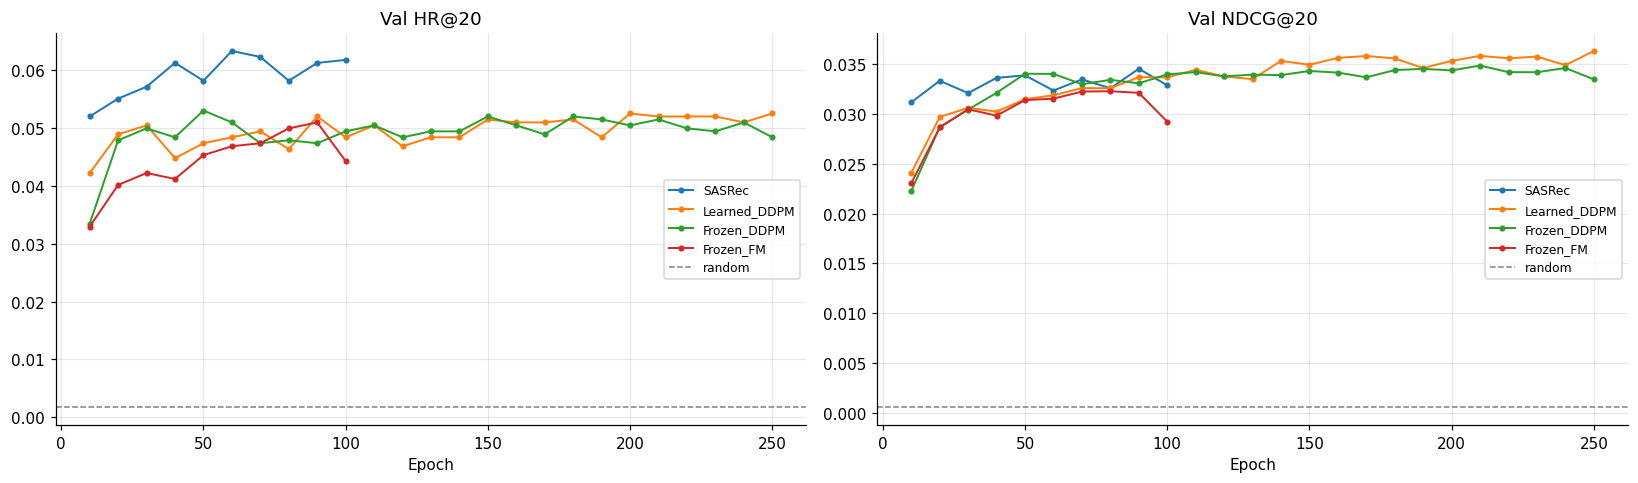

In [7]:
# ════════════════════════════════════════════════════════════
# Val HR@20 и NDCG@20 по эпохам
# ════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, entry in models.items():
    log_path = entry['ckpt_dir'] / 'log_val.csv'
    if not log_path.exists():
        print(f'{name}: нет {log_path}')
        continue
    log = pd.read_csv(log_path)
    log = log[log['epoch'].astype(str) != 'test'].apply(pd.to_numeric, errors='coerce')
    axes[0].plot(log['epoch'], log['HR@20'],   'o-', ms=3, lw=1.3, label=LABELS.get(name, name))
    axes[1].plot(log['epoch'], log['NDCG@20'], 'o-', ms=3, lw=1.3, label=LABELS.get(name, name))

for ax, title, rnd in [(axes[0], 'Val HR@20', random_row()['HR@20']),
                       (axes[1], 'Val NDCG@20', random_row()['NDCG@20'])]:
    ax.axhline(rnd, color='gray', ls='--', lw=1, label='random')
    ax.set_xlabel('Epoch'); ax.set_title(title); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## NDCG@20 против числа шагов сэмплинга

Сколько шагов реально нужно генеративным моделям. У DDPM это respaced ancestral sampling —
тот же стохастический reverse-процесс по равномерно прорежённой сетке из `num_steps`
таймстепов (при `num_steps ≥ T` — полная цепочка); у Flow Matching — число шагов Euler ODE.
SASRec не участвует: сэмплинга у него нет.

Стоимость свипа линейна по сумме шагов, поэтому сидов здесь меньше, чем в таблице выше.

Learned_DDPM    steps=1    NDCG@20 = 0.0350 ± 0.0003
Learned_DDPM    steps=5    NDCG@20 = 0.0377 ± 0.0001
Learned_DDPM    steps=10   NDCG@20 = 0.0379 ± 0.0003
Learned_DDPM    steps=25   NDCG@20 = 0.0380 ± 0.0006
Learned_DDPM    steps=50   NDCG@20 = 0.0388 ± 0.0005
Learned_DDPM    steps=100  NDCG@20 = 0.0389 ± 0.0002
Frozen_DDPM     steps=1    NDCG@20 = 0.0361 ± 0.0001
Frozen_DDPM     steps=5    NDCG@20 = 0.0393 ± 0.0002
Frozen_DDPM     steps=10   NDCG@20 = 0.0395 ± 0.0002
Frozen_DDPM     steps=25   NDCG@20 = 0.0398 ± 0.0002
Frozen_DDPM     steps=50   NDCG@20 = 0.0395 ± 0.0006
Frozen_DDPM     steps=100  NDCG@20 = 0.0398 ± 0.0001
Frozen_FM       steps=1    NDCG@20 = 0.0324 ± 0.0006
Frozen_FM       steps=5    NDCG@20 = 0.0333 ± 0.0001
Frozen_FM       steps=10   NDCG@20 = 0.0335 ± 0.0003
Frozen_FM       steps=25   NDCG@20 = 0.0336 ± 0.0004
Frozen_FM       steps=50   NDCG@20 = 0.0336 ± 0.0004
Frozen_FM       steps=100  NDCG@20 = 0.0335 ± 0.0004


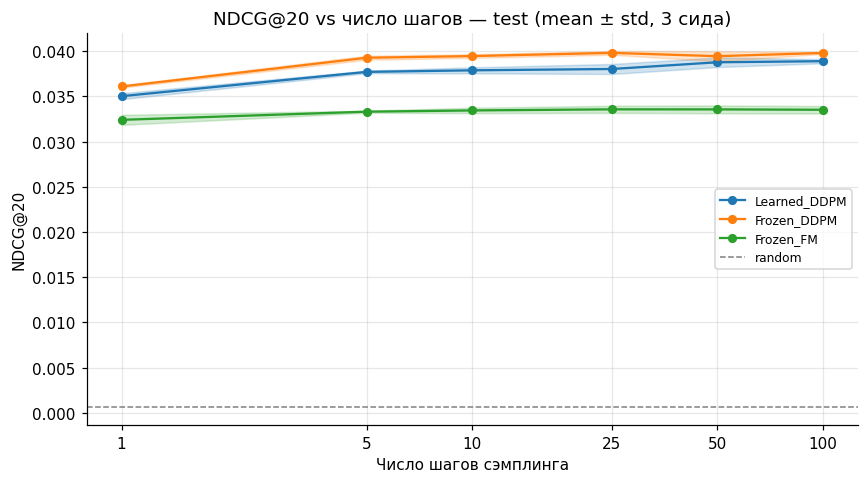

In [8]:
# ════════════════════════════════════════════════════════════
# Свип по числу шагов сэмплинга
# ════════════════════════════════════════════════════════════
STEP_LIST  = [1, 5, 10, 25, 50, 100]
STEP_SPLIT = 'test'
STEP_RUNS  = 3                       # сидов на точку

generative = {n: e for n, e in models.items() if e['generative']}
curves = {}

for name, entry in generative.items():
    means, stds = [], []
    for steps in STEP_LIST:
        vals = []
        for seed in seeds[:STEP_RUNS]:
            with seeded(seed, device):
                vals.append(evaluate(model=entry['model'], dataloader=entry['loaders'][STEP_SPLIT],
                                     top_k_values=TOP_K, num_sample_steps=steps,
                                     w_cfg=entry['w_cfg'], device=device,
                                     show_progress=False)['NDCG@20'])
        means.append(float(np.mean(vals))); stds.append(float(np.std(vals)))
        print(f'{LABELS.get(name, name):<15} steps={steps:<4} NDCG@20 = {means[-1]:.4f} ± {stds[-1]:.4f}')
    curves[name] = (np.array(means), np.array(stds))

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, (means, stds) in curves.items():
    line, = ax.plot(STEP_LIST, means, 'o-', lw=1.5, ms=5, label=LABELS.get(name, name))
    ax.fill_between(STEP_LIST, means - stds, means + stds, color=line.get_color(), alpha=0.2)
ax.axhline(random_row()['NDCG@20'], color='gray', ls='--', lw=1, label='random')
ax.set_xscale('log'); ax.set_xticks(STEP_LIST); ax.set_xticklabels(STEP_LIST); ax.minorticks_off()
ax.set_xlabel('Число шагов сэмплинга'); ax.set_ylabel('NDCG@20')
ax.set_title(f'NDCG@20 vs число шагов — {STEP_SPLIT} (mean ± std, {STEP_RUNS} сида)')
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()